# HPP: gpt-oss-20b

24 layers all-MoE - 32 routed experts, top-4 - D=2880, d=2880 - fused interleaved gate_up + harmony chat template

**Hierarchy:** `total budget -> layer budgets (ALPHA) -> dynamic expert drop (gamma floors) -> survivor widths (BETA) -> channels`

| symbol | role |
|---|---|
| `gamma` | per-expert energy-retention threshold -> sets each expert's channel FLOOR |
| `alpha` | LAYER allocation exponent (depth-aware budget split) |
| `beta`  | EXPERT allocation exponent (saliency-weighted survivor widths) |

Special cases recovered: high gamma -> REAP (drop whole experts); 

All logic lives in the `hpp` package, this notebook only chooses knobs and calls runners. Every step is cached and resumable.

### 1: Setup

`CUDA_VISIBLE_DEVICES` must be set before torch is imported, which is why it cannot live inside the config.

In [ ]:
import os
import sys
from pathlib import Path

GPU_ID = "1"
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID

root = Path.cwd()
if not (root / "hpp").exists() and (root.parent / "hpp").exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))


from hpp.models import build
from hpp import runners, gamma as gamma_mod, reconstruction
from hpp.floors import gamma_to_floors
from hpp.plots.saliency import plot_floors
from hpp.plots.pca import pca_functional_subspace
from hpp.results import before_after_table

cfg, adapter = build("gptoss20b", quantize=False)
print(cfg.model_tag, cfg.prec_tag, "| sparsities", cfg.sparsities,
      "| recon", cfg.recon.sparsities)
print("results ->", cfg.res_dir)

gptoss20b bf16 | sparsities (0.25, 0.5, 0.75) | recon (0.75,)
results -> results_gptoss_bf16


### 2: profile, to scores, to diagnostics

One forward pass over the packed calibration set fills every statistic the three saliency levels need. Cached per (model, precision, calibration shape); the GPU is freed before returning.

Emits: layer-importance bars (ALPHA driver), expert-saliency heatmap (BETA driver), REAP-saliency heatmap (the baseline's own scoring), and the three convergence panels.

cache hit (scores + profile) [bf16]
  [guard] 0 experts below the activation floor, 0 leak (must be 0)


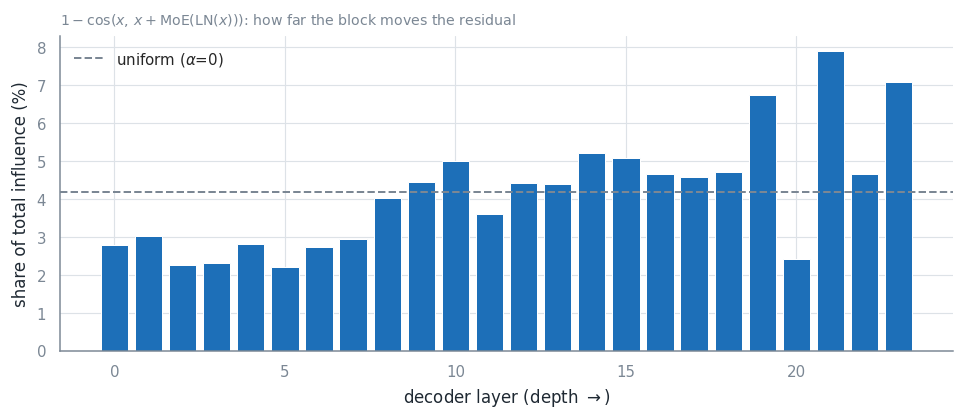

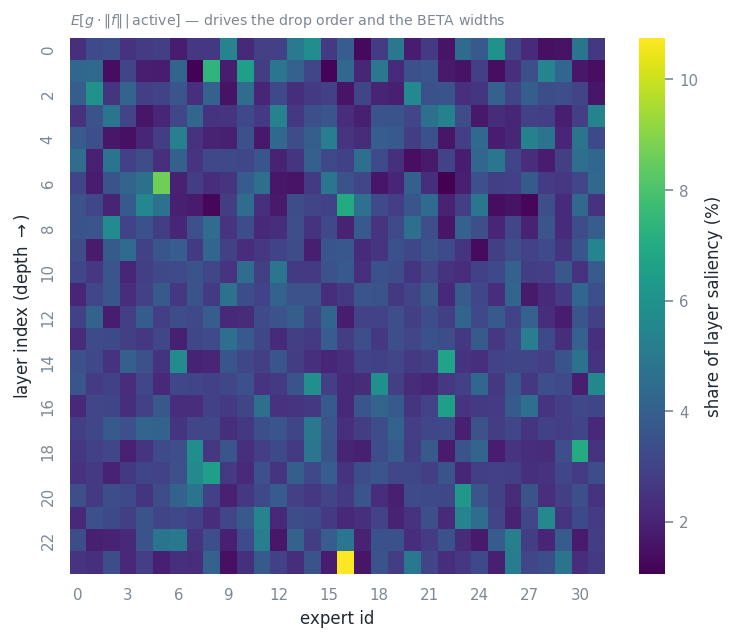

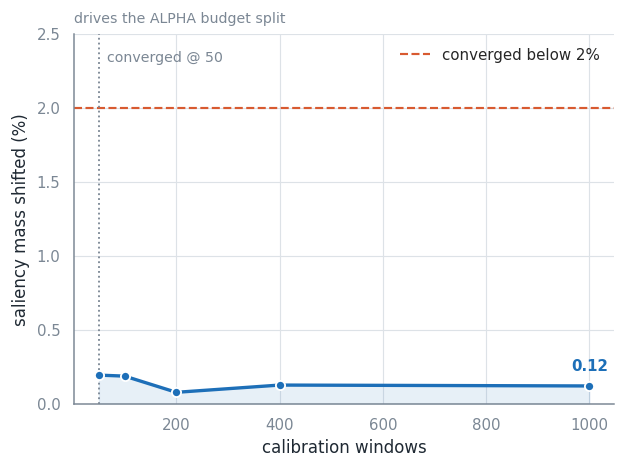

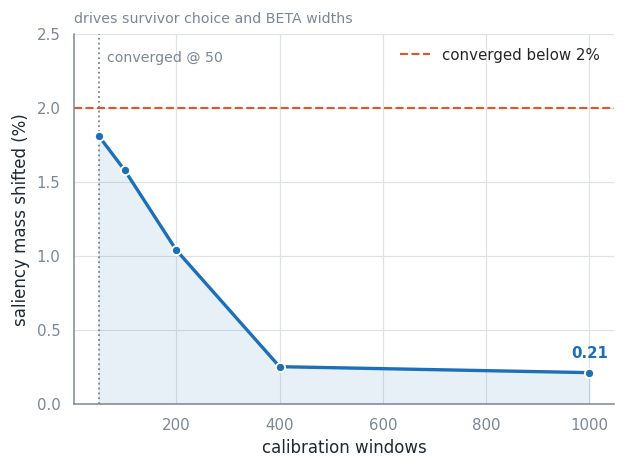

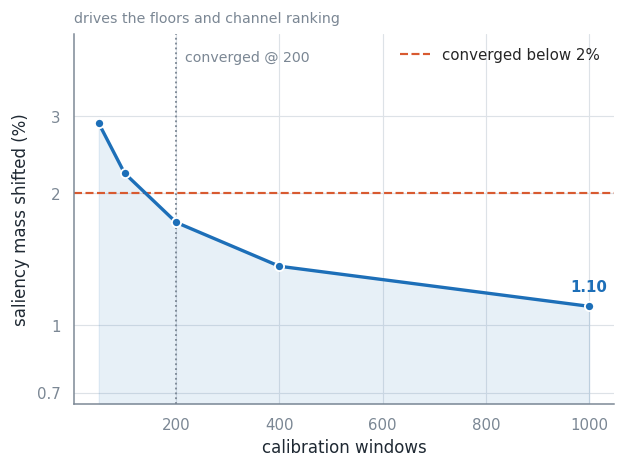

In [2]:
scores, prof = runners.setup(cfg, adapter)

### 3: calibrate gamma

gamma is **read off the model**, not chosen: probe the whole-expert cliff on GPU to find how many experts this model actually tolerates (m*), then pick the gamma whose floors reproduce m* offline. Skip by setting `cfg.gamma = <value>` directly.

  answer key @ s=50%: best perplexity=1194.7513 (lower is better), threshold=1327.5014 -> 24 survivors (drop 8)
  -> calibrated gamma = 0.923 (mean floor 66.1% of D)


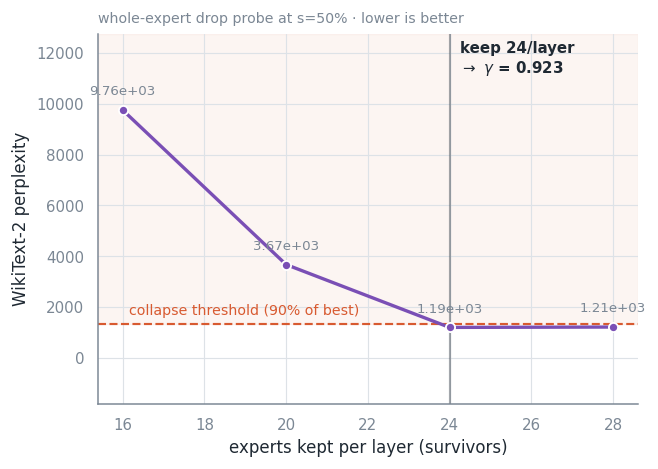

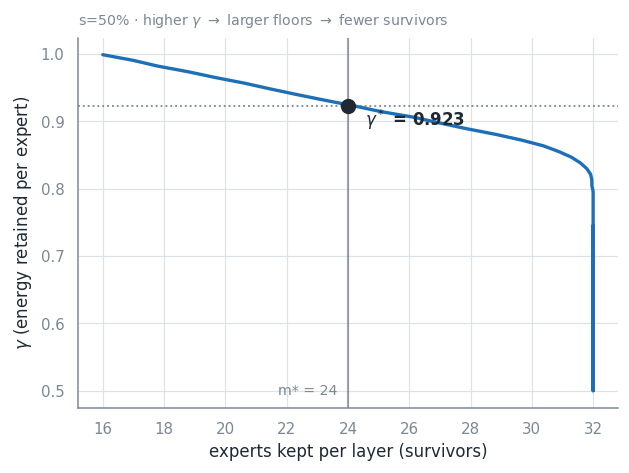

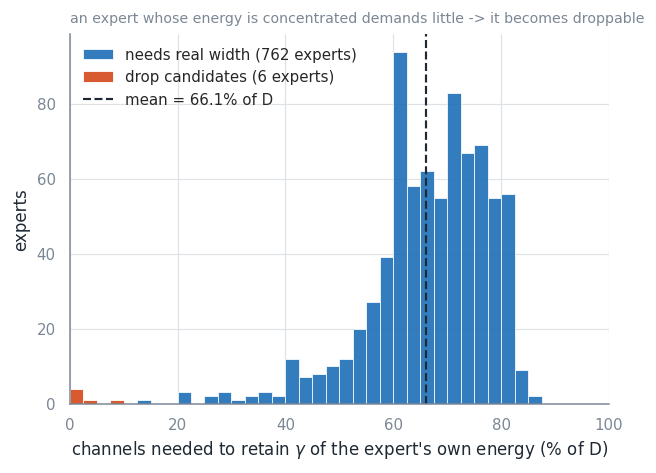

gamma = 0.9228813559322033


In [3]:
if cfg.gamma is None:
    if not cfg.dropkey_csv.exists():
        gamma_mod.ensure_drop_keys(cfg, adapter, scores)   # GPU: reloads the model per probe
    cfg.gamma, curve = gamma_mod.calibrate_gamma(cfg, scores)

plot_floors(cfg, gamma_to_floors(cfg, scores, cfg.gamma), cfg.gamma)
print("gamma =", cfg.gamma)

### 4: functional subspace (REAP Fig. 1 analogue)

Does the surviving set still span the original experts' output space? One PCA per layer, three panels sharing coordinates: Original / REAP / HPP.

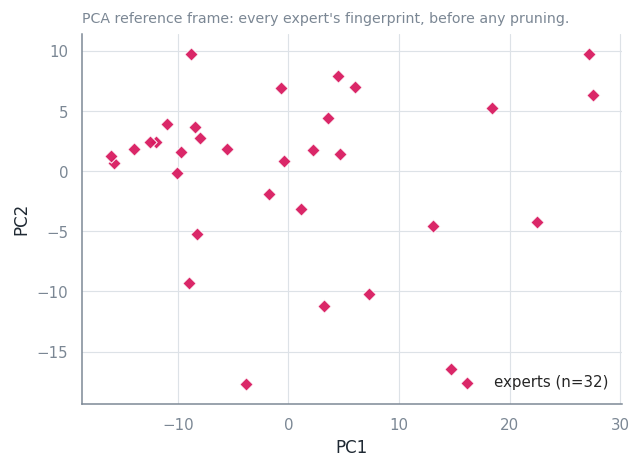

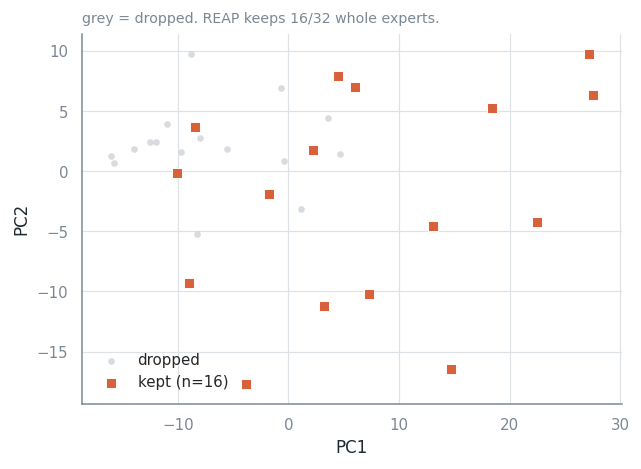

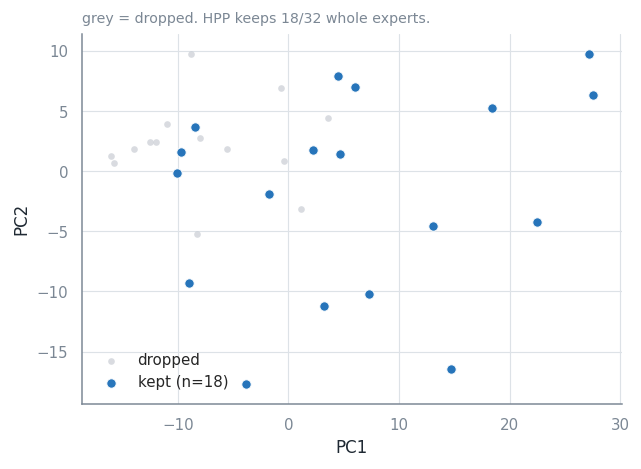

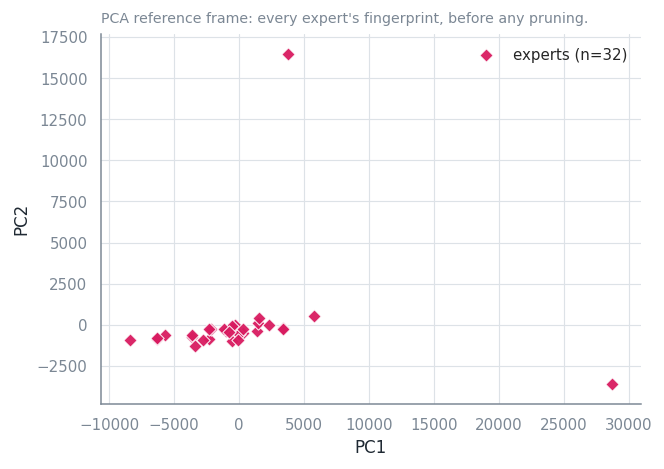

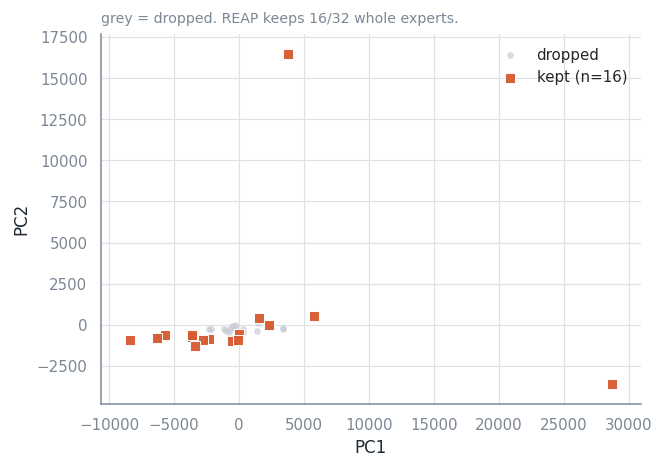

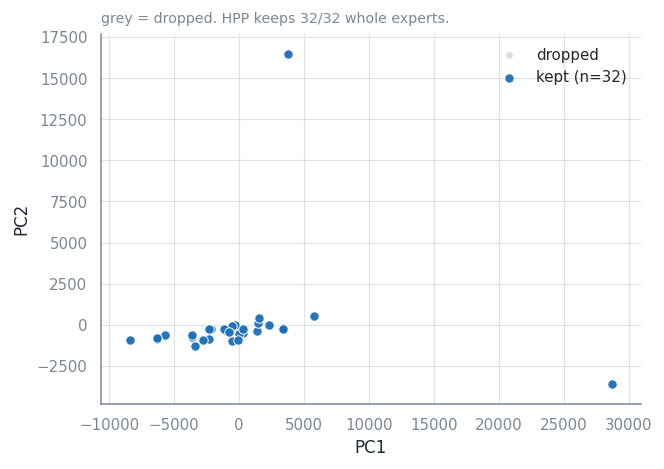


  PC1+PC2 cumulative variance explained (cf. REAP Table A4):
 layer_id  evr_original  evr_reap  evr_hpp  reap_survivors  hpp_survivors
        0        0.6005    0.6152   0.6093              16             18
       23        0.7695    0.8282   0.7695              16             32


,layer_id,evr_original,evr_reap,evr_hpp,reap_survivors,hpp_survivors
0,0,0.6005,0.6152,0.6093,16,18
1,23,0.7695,0.8282,0.7695,16,32


In [4]:
pca_functional_subspace(cfg, scores, sparsity=0.50)

### 5: baseline + sweep
Every sparsity point goes through `run_hpp`/`run_reap`, so each one leaves its allocation CSV, pruned-index NPZ and kept-capacity heatmap behind — not just a CSV row.

In [5]:
PROFILE = "fast_sweep"

runners.run_baseline(cfg, adapter, PROFILE)

  [skip] baseline



SWEEP [bf16] gptoss20b: alpha=1.0 beta=1.0 gamma=0.923 profile=fast_sweep
  [skip] HPP s=25% a=1.0 b=1.0
  [skip] REAP s=25%
  [skip] HPP s=50% a=1.0 b=1.0
  [skip] REAP s=50%
  [skip] HPP s=75% a=1.0 b=1.0
  [skip] REAP s=75%


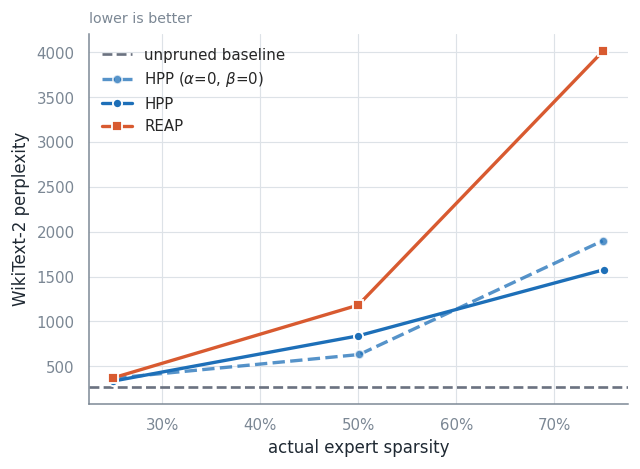

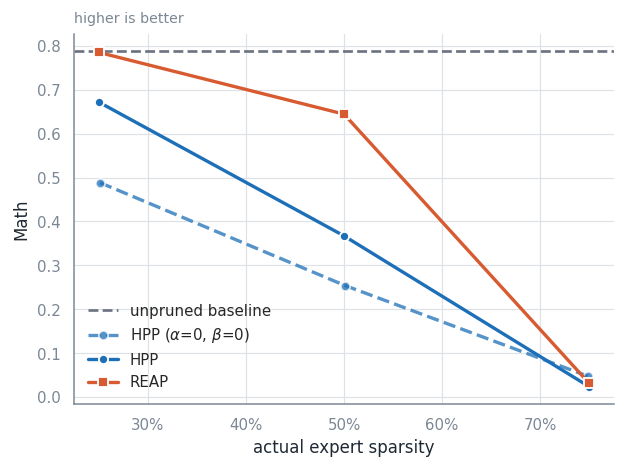

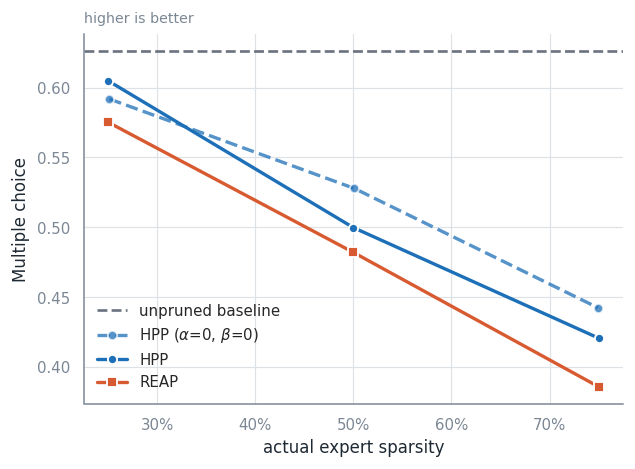

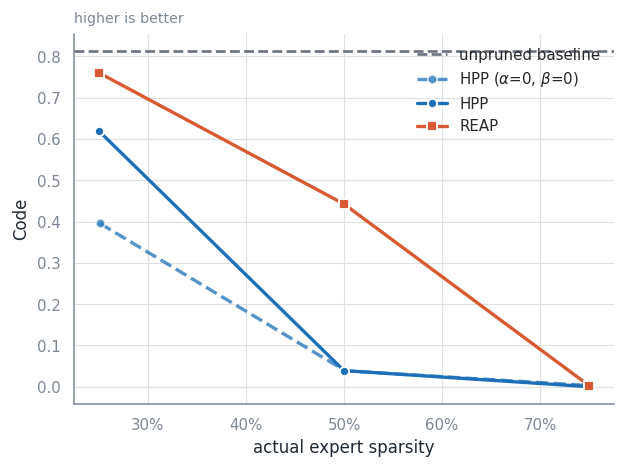

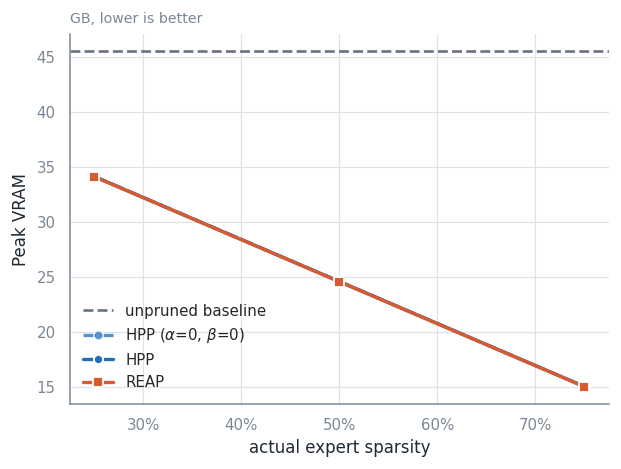

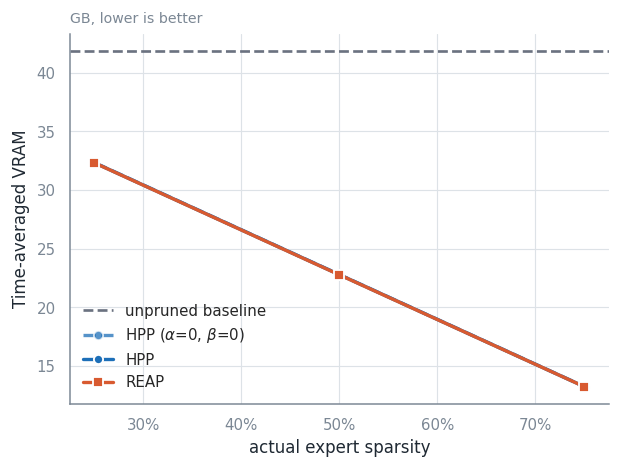

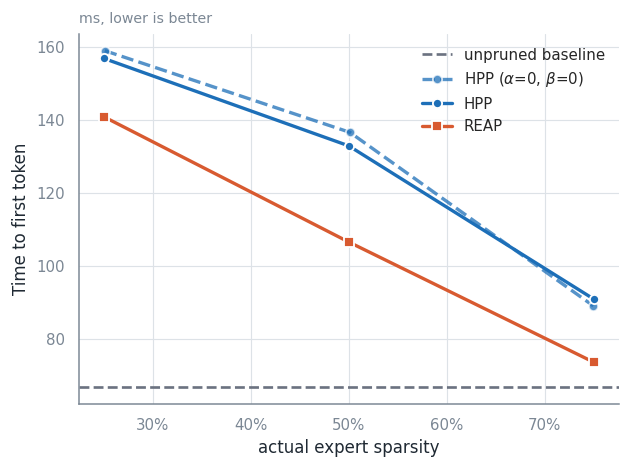

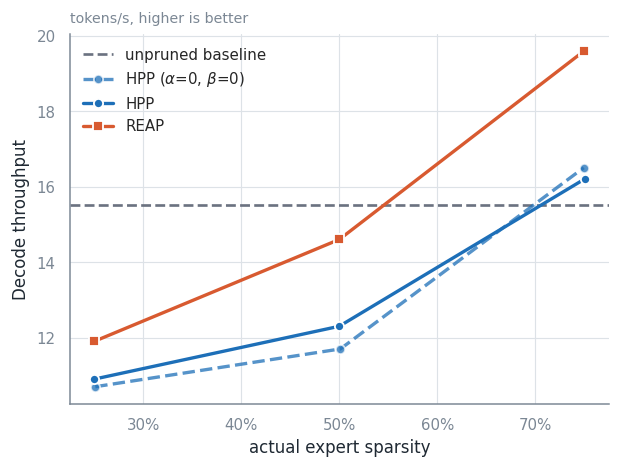

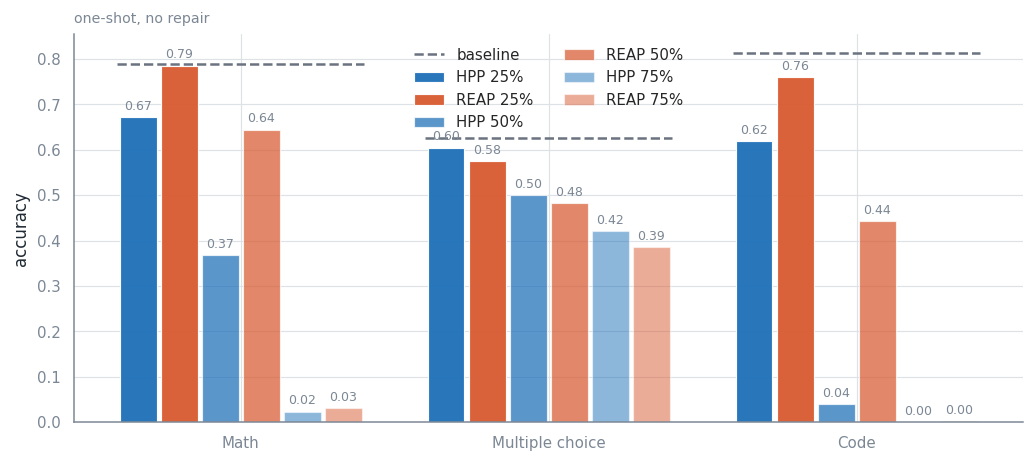

In [6]:
runners.run_sweep(cfg, adapter, scores, profile=PROFILE)

### Ablation: uniform allocation (alpha = beta = 0)

Isolates what the depth-aware and saliency-weighted allocation actually buy over spending the same budget uniformly.


SWEEP [bf16] gptoss20b: alpha=0.0 beta=0.0 gamma=0.923 profile=fast_sweep
  [skip] HPP s=25% a=0.0 b=0.0
  [skip] REAP s=25%
  [skip] HPP s=50% a=0.0 b=0.0
  [skip] REAP s=50%
  [skip] HPP s=75% a=0.0 b=0.0
  [skip] REAP s=75%


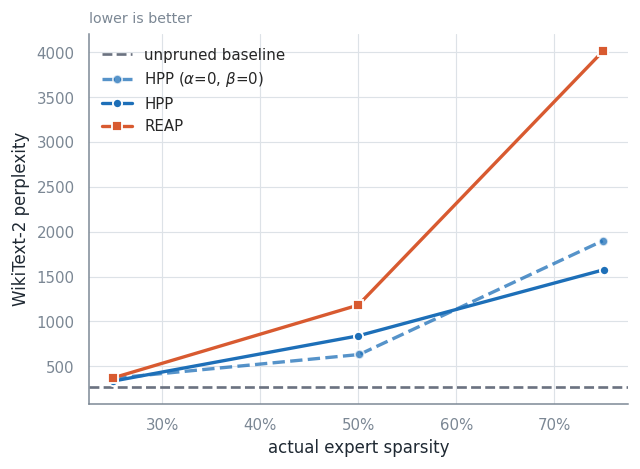

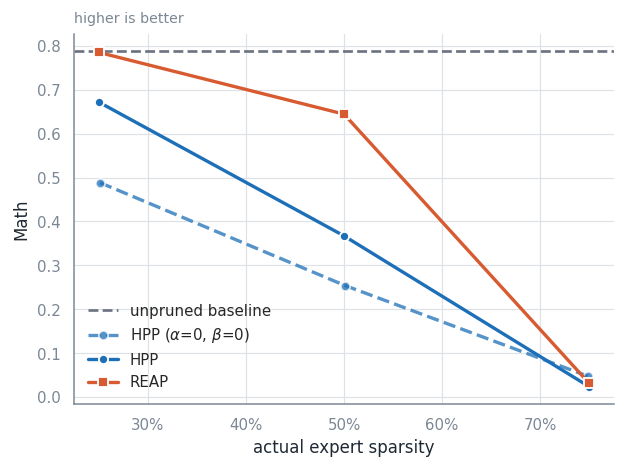

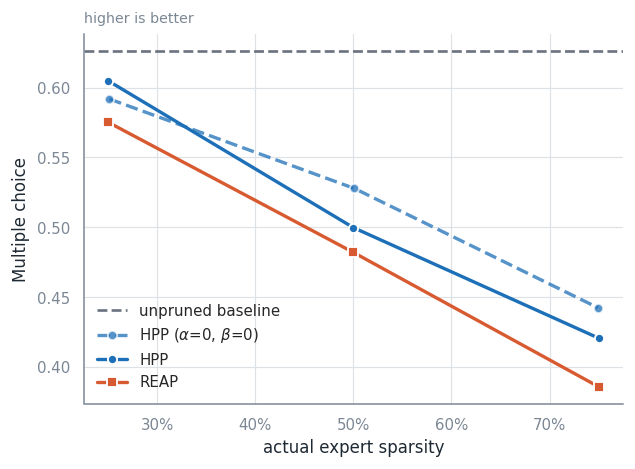

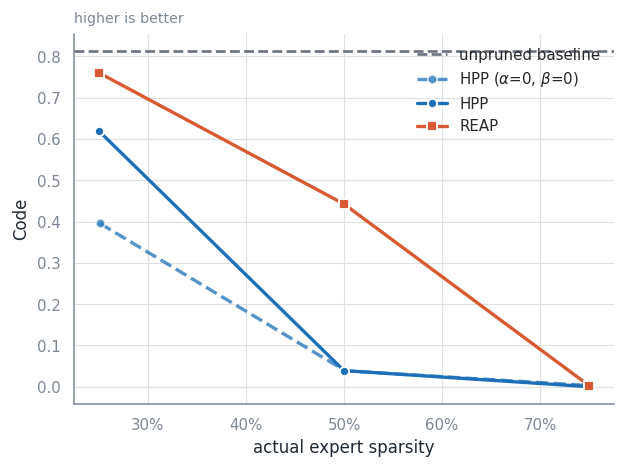

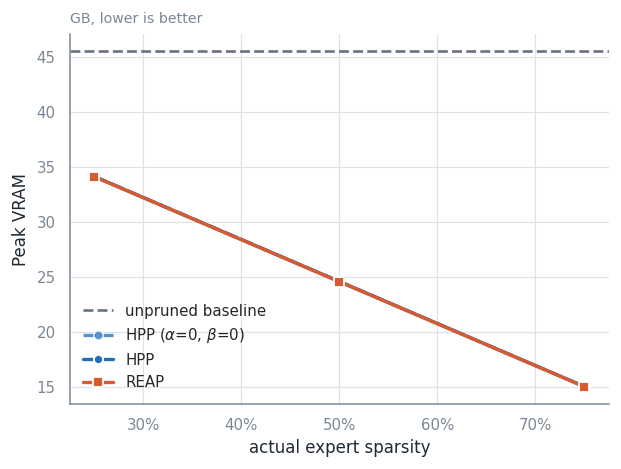

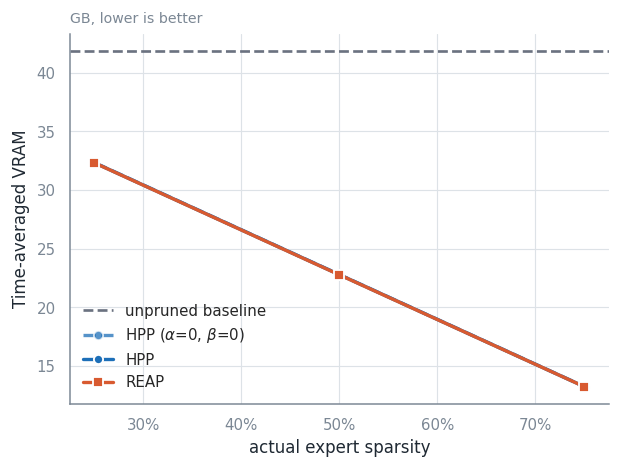

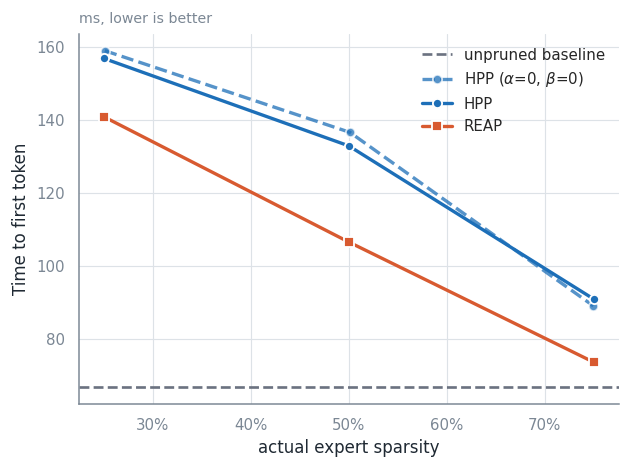

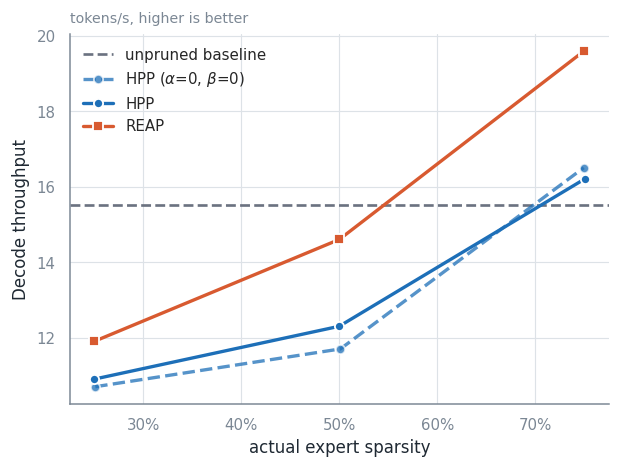

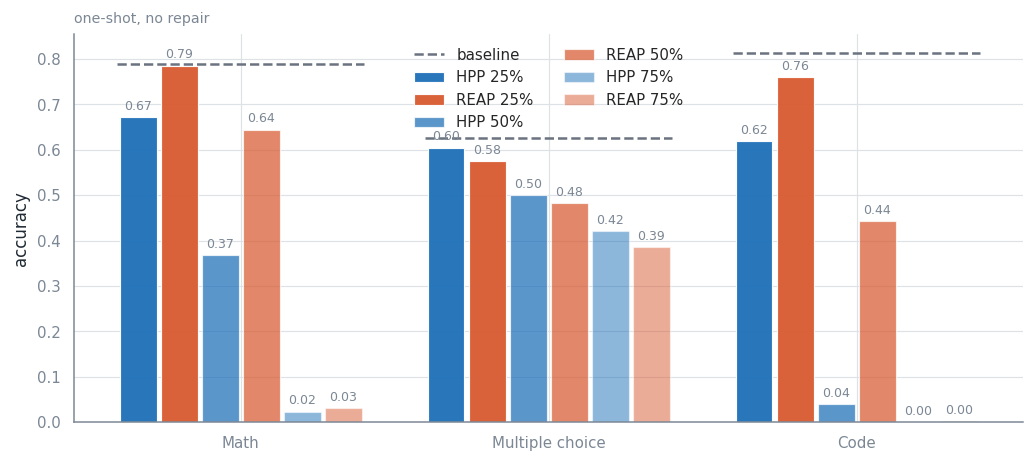

In [7]:
runners.run_sweep(cfg, adapter, scores, alpha=0.0, beta=0.0, profile=PROFILE)

### 6: LoRA reconstruction (C4)

Does HPP's channel selection leave more *repairable* structure than REAP's whole-expert selection? LoRA on surviving experts' gate/up/down only; router and attention frozen. Identical seed, data order and schedule for both methods.

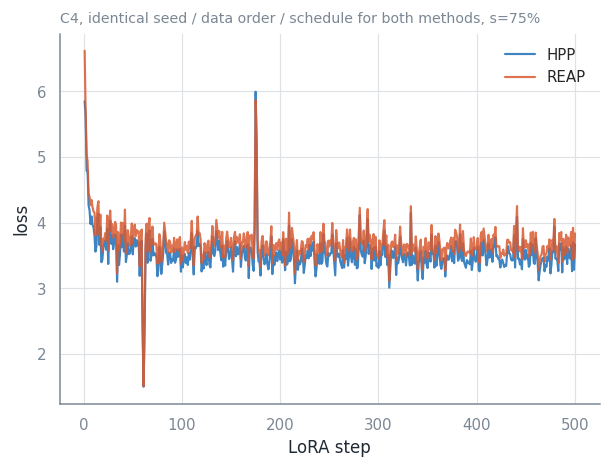

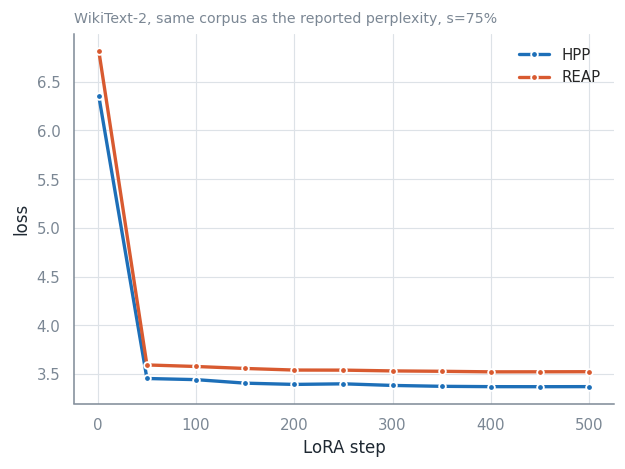

  [WARNING] 2 rows match hpp s=75% (alpha/beta: [(1.0, 1.0), (0.0, 0.0)]) -- using the first
  [skip] repaired hpp s=75% already logged
  [skip] repaired reap s=75% already logged
Method Sparsity  perplexity (before)  perplexity (after)  recovered %
   HPP    75.0%            1575.4634             19.8709         98.7
  REAP    75.0%            4018.1785             23.3224         99.4


,Method,Sparsity,perplexity (before),perplexity (after),recovered %
0,HPP,75.0%,1575.4634,19.8709,98.7
1,REAP,75.0%,4018.1785,23.3224,99.4


In [8]:
reconstruction.run_all_reconstructions(cfg, adapter, scores)

for s in cfg.recon.sparsities:
    for m in ("hpp", "reap"):
        reconstruction.evaluate_repaired(cfg, adapter, scores, m, s)

before_after_table(cfg, PROFILE, "perplexity")

### 7: math-trained reconstruction ablation: HPP vs REAP, s=75%

Smoke tests above confirmed the pipeline runs and the harmony-format bug is fixed. This runs the real thing: full 500-step math-domain LoRA repair for both methods at both sparsities, then diffs against the unrepaired 'before' row for perplexity/gsm8k/math500/code_avg. Own CSV (`ablation_math_reconstruction.csv`), own per-sparsity figures doesn't touch `sweep.csv`/`sweep_reconstructed.csv`.

  [skip] math-recon training hpp s=75% already done (lora_mathrecon_hpp_s75_gptoss20b.pt exists)
  [WARNING] 2 rows match hpp s=75% (alpha/beta: [(1.0, 1.0), (0.0, 0.0)]) -- using the first
  [skip] math-recon eval hpp s=75% already logged
  [skip] math-recon training reap s=75% already done (lora_mathrecon_reap_s75_gptoss20b.pt exists)
  [skip] math-recon eval reap s=75% already logged
  [WARNING] 2 rows match hpp s=75% (alpha/beta: [(1.0, 1.0), (0.0, 0.0)]) -- using the first
  [WARNING] 2 rows match hpp s=75% (alpha/beta: [(1.0, 1.0), (0.0, 0.0)]) -- using the first


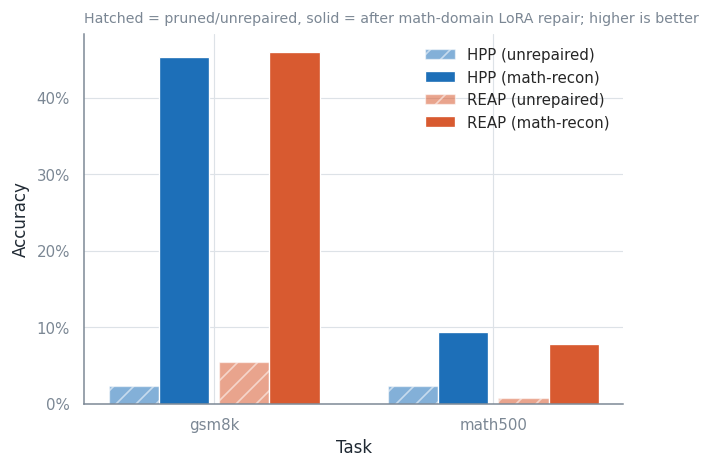

In [9]:
from hpp import ablation

math_recon_df = ablation.run_math_reconstruction_ablation(cfg, adapter, scores, sparsity=(0.75))